Data retrieved from frost.met.no!

--- Temperaturstatistikk Ås (2025) ---
 Mean  Median   Min  Max
  7.9    8.35 -16.1 24.5


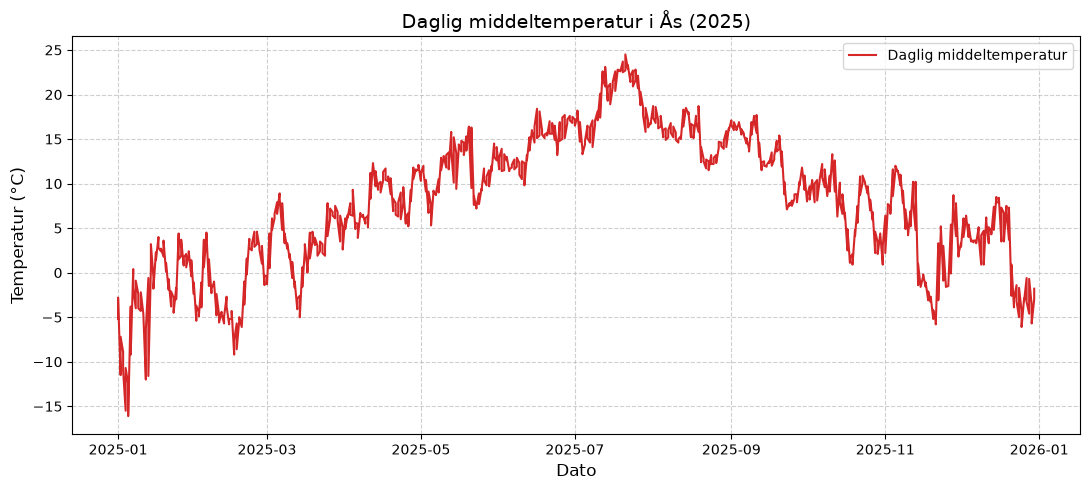

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

# Les client_id
with open("../client_id.py", "r") as f:
    client_id = f.read().strip()

# Sett opp API-kall til Frost
endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Send HTTP GET request (Frost krever client_id som brukernavn i Basic Auth)
r = requests.get(endpoint, params=parameters, auth=(client_id, ""))
json_data = r.json()


if r.status_code == 200:
    raw_data = json_data["data"]
    print("Data retrieved from frost.met.no!")

    # Bygg opp liste med rader
    rows = []
    for item in raw_data:
        ref_time = item["referenceTime"]
        source_id = item["sourceId"]
        for obs in item["observations"]:
            rows.append(
                {
                    "referenceTime": pd.to_datetime(ref_time),
                    "sourceId": source_id,
                    "temperature": obs["value"],
                }
            )

    # Opprett DataFrame fra listen
    df_temp = pd.DataFrame(rows)

    # Lag oppsummeringstabell 
    summary_table = pd.DataFrame(
        {
            "Mean": [df_temp["temperature"].mean()],
            "Median": [df_temp["temperature"].median()],
            "Min": [df_temp["temperature"].min()],
            "Max": [df_temp["temperature"].max()],
        }
    )

    print("\n--- Temperaturstatistikk Ås (2025) ---")
    print(summary_table.round(2).to_string(index=False))

    # Lag plott for daglig middeltemperatur
    plt.figure(figsize=(11, 5))
    plt.plot(
        df_temp["referenceTime"],
        df_temp["temperature"],
        color="tab:red",
        linewidth=1.5,
        label="Daglig middeltemperatur",
    )

    plt.title("Daglig middeltemperatur i Ås (2025)", fontsize=14)
    plt.xlabel("Dato", fontsize=12)
    plt.ylabel("Temperatur (°C)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print(f"Error! Returned status code {r.status_code}")
    print("Message:", json_data.get("error", {}).get("message", "Ukjent feil"))
    print("Reason:", json_data.get("error", {}).get("reason", "Ingen grunn oppgitt"))

Data retrieved successfully from frost.met.no!

--- Nedbørstatistikk Ås (2025) ---
 Totalt (mm)  Snitt per dag (mm)  Maks på én dag (mm)
      3784.8                 5.2                 63.2


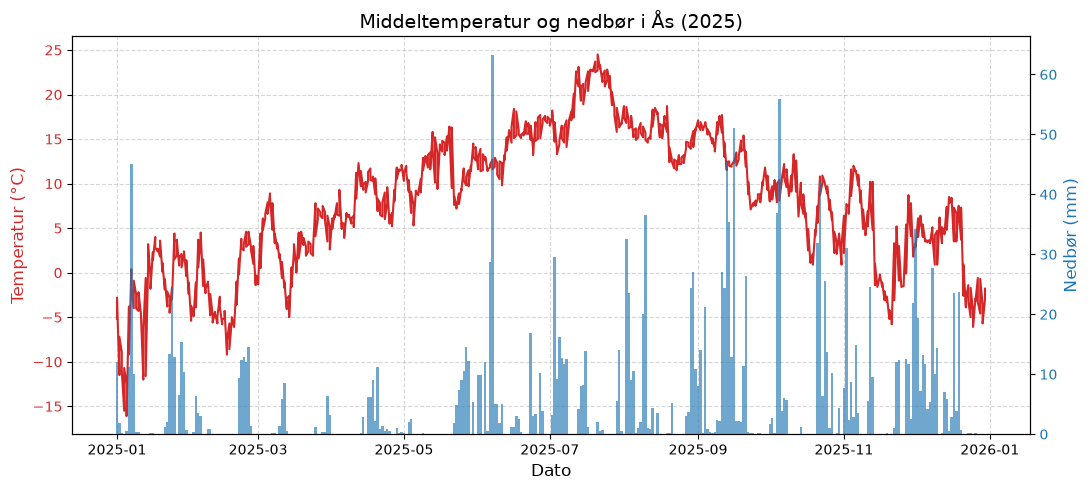

In [ ]:
# Task 02 Precipitation

precip_params = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Send API-kall
r_precip = requests.get(endpoint, params=precip_params, auth=(client_id, ""))

if r_precip.status_code == 200:
    print("Data retrieved successfully from frost.met.no!")

    # --- 4. Behandle nedbørdata ---
    precip_rows = []
    for item in r_precip.json()["data"]:
        ref_time = item["referenceTime"]
        for obs in item["observations"]:
            precip_rows.append(
                {
                    "referenceTime": pd.to_datetime(ref_time).tz_localize(None),
                    "precipitation": obs["value"],
                }
            )

    df_precip = pd.DataFrame(precip_rows)
    df_precip = (
        df_precip.groupby("referenceTime", as_index=False)["precipitation"]
        .mean()
        .reset_index(drop=True)
    )

    df_temp["referenceTime"] = pd.to_datetime(df_temp["referenceTime"]).dt.tz_localize(
    None
)

    # --- 5. Slå sammen tabellene trygt på dato (referenceTime) ---
    df_2025 = pd.merge(df_temp, df_precip, on="referenceTime", how="inner")

 

    precip_summary = pd.DataFrame(
        {
            "Totalt (mm)": [df_2025["precipitation"].sum()],
            "Snitt per dag (mm)": [df_2025["precipitation"].mean()],
            "Maks på én dag (mm)": [df_2025["precipitation"].max()],
        }
    )



    print("\n--- Nedbørstatistikk Ås (2025) ---")
    print(precip_summary.round(2).to_string(index=False))

    # --- 7. Plotting ---
    fig, ax1 = plt.subplots(figsize=(11, 5))

    # Temperatur (rød linje)
    color = "tab:red"
    ax1.set_xlabel("Dato", fontsize=12)
    ax1.set_ylabel("Temperatur (°C)", color=color, fontsize=12)
    ax1.plot(
        df_2025["referenceTime"],
        df_2025["temperature"],
        color=color,
        linewidth=1.5,
        label="Daglig middeltemperatur",
    )
    ax1.tick_params(axis="y", labelcolor=color)
    ax1.grid(True, linestyle="--", alpha=0.5)

    # Nedbør (blå søyler)
    ax2 = ax1.twinx()
    color = "tab:blue"
    ax2.set_ylabel("Nedbør (mm)", color=color, fontsize=12)
    ax2.bar(
        df_2025["referenceTime"],
        df_2025["precipitation"],
        color=color,
        alpha=0.4,
        width=1.0,
        label="Daglig nedbør",
    )
    ax2.tick_params(axis="y", labelcolor=color)

    plt.title("Middeltemperatur og nedbør i Ås (2025)", fontsize=14)
    fig.tight_layout()
    plt.show()

else:
    print(
        f"Feil ved henting av data. Statuskoder: Temp={r_temp.status_code}, Precip={r_precip.status_code}"
    )

Data retrieved successfully from frost.met.no!

--- Historiske temperaturdata Ås (1925 vs 2025) ---
   day_of_year  temp_1925 date_str  temp_2025
0            1        1.3    01.01      -4.00
1            2        4.1    02.01      -9.35
2            3        2.1    03.01      -9.95
3            4        0.1    04.01     -13.10
4            5       -2.2    05.01     -14.30


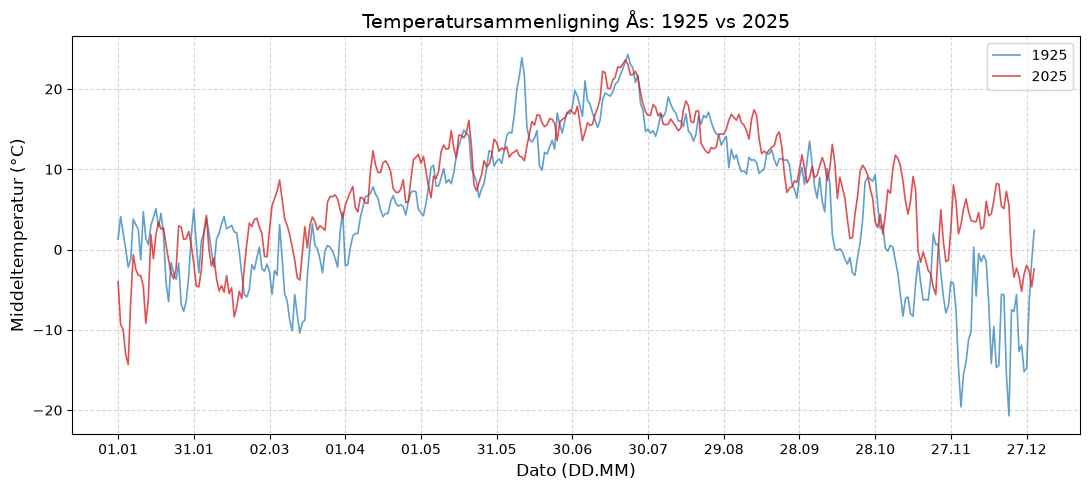

In [3]:
# Task 03 Historical temperature data

temp_params1 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

temp_params2 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1925-12-31",
}

r_temp = requests.get(endpoint, params=temp_params1, auth=(client_id, ""))
r_temp2 = requests.get(endpoint, params=temp_params2, auth=(client_id, ""))

if r_temp.status_code == 200 and r_temp2.status_code == 200:
    print("Data retrieved successfully from frost.met.no!")

    temp_rows = []
    for item in r_temp.json()["data"]:
        ref_time = item["referenceTime"]
        for obs in item["observations"]:
            temp_rows.append(
                {
                    "referenceTime": pd.to_datetime(ref_time).tz_localize(None),
                    "temperature": obs["value"],
                }
            )
    
    df_temp_2025 = pd.DataFrame(temp_rows)
    df_temp_2025 = (df_temp_2025.groupby("referenceTime", as_index=False)["temperature"].mean().reset_index(drop=True))

    temp_rows2 = []
    for item in r_temp2.json()["data"]:
        ref_time = item["referenceTime"]
        for obs in item["observations"]:
            temp_rows2.append(
                {
                    "referenceTime": pd.to_datetime(ref_time).tz_localize(None),
                    "temperature": obs["value"],
                }
            )

    df_temp_1925 = pd.DataFrame(temp_rows2)
    df_temp_1925 = (df_temp_1925.groupby("referenceTime", as_index=False)["temperature"].mean().reset_index(drop=True))

    df_temp_2025["Year"] = 2025
    df_temp_1925["Year"] = 1925


    df_combined = pd.concat([df_temp_2025, df_temp_1925], ignore_index=True)# Hent ut Måned-Dag (MM-DD) og Dag i året for kobling
    df_temp_2025["day_of_year"] = df_temp_2025["referenceTime"].dt.dayofyear
    df_temp_2025["date_str"] = df_temp_2025["referenceTime"].dt.strftime("%d.%m")

    df_temp_1925["day_of_year"] = df_temp_1925["referenceTime"].dt.dayofyear

    # Slå sammen på dag i året
    df_historical = pd.merge(
        df_temp_1925[["day_of_year", "temperature"]].rename(
            columns={"temperature": "temp_1925"}
        ),
        df_temp_2025[["day_of_year", "date_str", "temperature"]].rename(
            columns={"temperature": "temp_2025"}
        ),
        on="day_of_year",
        how="inner",
    )
    print("\n--- Historiske temperaturdata Ås (1925 vs 2025) ---")
    print(df_historical.head())

    # Plotting med Måned-Dag på x-aksen
    plt.figure(figsize=(11, 5))
    plt.plot(
        df_historical["date_str"],
        df_historical["temp_1925"],
        label="1925",
        color="tab:blue",
        alpha=0.7,
        linewidth=1.2,
    )
    plt.plot(
        df_historical["date_str"],
        df_historical["temp_2025"],
        label="2025",
        color="tab:red",
        alpha=0.8,
        linewidth=1.2,
    )

    plt.title("Temperatursammenligning Ås: 1925 vs 2025", fontsize=14)
    plt.xlabel("Dato (DD.MM)", fontsize=12)
    plt.ylabel("Middeltemperatur (°C)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)

    # Vis kun f.eks. hver 30. dato på x-aksen så teksten ikke overlapper
    plt.xticks(
        range(0, len(df_historical), 30),
        df_historical["date_str"].iloc[::30]
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Feil ved henting av data.")





In [4]:
# Task 04 Heatwaves

def count_heatwaves(
    source_id: str, year: int, output_filename: str = "heatwaves_summary.yml"
):
    """Counts the number of heatwaves per year and outputs YAML matching the exact template."""

    temp_params1 = {
        "sources": source_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31",
    }

    r_temp = requests.get(endpoint, params=temp_params1, auth=(client_id, ""))
    if r_temp.status_code != 200:
        print(f"Error! Returned status code {r_temp.status_code}")
        return None

    json_data = r_temp.json()
    raw_data = json_data.get("data", [])

    rows = []
    for item in raw_data:
        ref_time = item["referenceTime"]
        for obs in item["observations"]:
            rows.append(
                {
                    "referenceTime": pd.to_datetime(ref_time).tz_localize(
                        None
                    ),
                    "temperature": obs["value"],
                }
            )

    heatwave_ranges = []

    if df_empty := (len(rows) == 0):
        print(f"No observations found for source {source_id} in year {year}.")
    else:
        df = pd.DataFrame(rows)
        df = df.sort_values("referenceTime").reset_index(drop=True)

        current_wave = []

        for idx, row in df.iterrows():
            temp = row["temperature"]
            date_str = row["referenceTime"].strftime("%Y-%m-%d")

            if temp >= 27.0:
                current_wave.append(date_str)
            else:
                if len(current_wave) >= 5:
                    # Legger til 'START_DATO - SLUTT_DATO'
                    heatwave_ranges.append(
                        f"{current_wave[0]} - {current_wave[-1]}"
                    )
                current_wave = []

        # Håndter hetebølge som strekker seg helt ut året
        if len(current_wave) >= 5:
            heatwave_ranges.append(f"{current_wave[0]} - {current_wave[-1]}")

    # Bygg ordboken eksakt slik at nøklene matcher eksempelet
    summary_data = {
        "dates": heatwave_ranges,
        "station_id": source_id,
        "station_name": "Ås",
    }

    # Lagre til YAML
    with open(output_filename, "w", encoding="utf-8") as yml_file:
        yaml.dump(
            summary_data,
            yml_file,
            default_flow_style=False,
            sort_keys=False,
            allow_unicode=True,
        )

    print(f"Sammendrag lagret til {output_filename}")
    return len(heatwave_ranges)


antall = count_heatwaves("SN17850", 2025)
print(f"Antall hetebølger: {antall}")

Sammendrag lagret til heatwaves_summary.yml
Antall hetebølger: 1


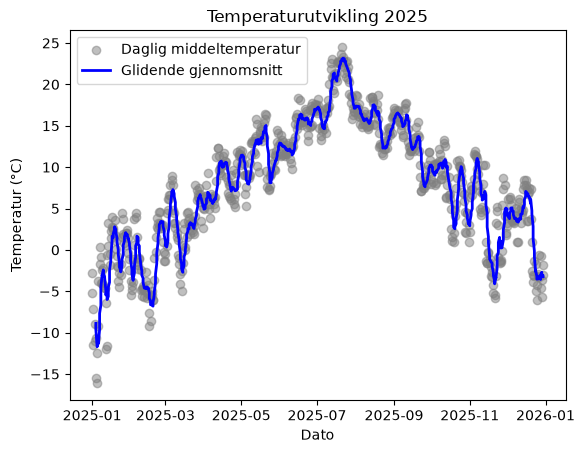

In [5]:
# Task 05 Glidende gjennomsnitt

def calculate_moving_average(df, window_size=7):
    '''Calculates the moving average temperature for a period of 7 days'''
    df_sorted = df.sort_values("referenceTime").reset_index(drop=True)
    return df_sorted["temperature"].rolling(window=window_size).mean()

# Bruker funksjonen på 2025 fra task 01

df_2025["moving_average"] = calculate_moving_average(df_2025, window_size=7)

# Plotter daglig temp
plt.scatter(df_2025["referenceTime"], df_2025["temperature"], color="gray", alpha=0.5, label="Daglig middeltemperatur")
# Plotter glidende gjennomsnitt
plt.plot(df_2025["referenceTime"], df_2025["moving_average"], color="blue", linewidth=2, label="Glidende gjennomsnitt")
plt.xlabel("Dato")
plt.ylabel("Temperatur (°C)")
plt.title("Temperaturutvikling 2025")
plt.legend()
plt.show()
